## LAB 3 - TASK 3 submission. Artificial Intelligence 2026-27

**NAME AND NIP**: Jorge Ruiz (826685) and Hugo López (875455)


## 3. Fine-tuning
We adapt an ImageNet-pretrained MobileNetV2 to the five food classes from Task 2.

1. **Feature extraction:** freeze the backbone and train the new five-class output layer.
2. **Fine-tuning:** unfreeze the backbone and adapt its features with a smaller learning rate.
3. **Two variations:** compare a lower fine-tuning learning rate and training only the last 20 backbone layers (excluding BatchNormalization).

This follows the feature-extraction/fine-tuning distinction in Lecture 4.1, *CNNs*, PDF pages 67-74, and the supplied starter notebook.

All code cells were executed in order on the original 5,000-image dataset, using seed 123, batch size 4 and five epochs per stage. The run used TensorFlow 2.20.0 / Keras 3.12.4 on CPU. Training curves and the summary below contain the recorded results. Validation accuracy is used for comparison; there is no separate food test set in this exercise.


## Get data and tensorflow imports ready



In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras import backend as K

from tensorflow.keras import optimizers
from tensorflow.keras.applications import VGG16

import matplotlib.pyplot as plt

# Fix initialization and random operations for this recorded run.
tf.keras.utils.set_random_seed(123)


In [2]:
# GET YOUR IMAGES READY
# Use exactly the same five-class dataset as Task 2, not a new sample of images.
# Local option: dataset/<class>/<image> beside this notebook (images/ is also accepted).
# Colab option: the original folder in Google Drive.
from pathlib import Path

local_data_path = Path('dataset') if Path('dataset').is_dir() else Path('images')
if local_data_path.is_dir():
    drive_data_path = str(local_data_path)
else:
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError(
            'Place the original five-class dataset in dataset/ or run in Colab with the Drive folder below.'
        ) from None
    drive.mount('/content/drive')
    drive_data_path = '/content/drive/MyDrive/IA_p3_images/'

if not Path(drive_data_path).is_dir():
    raise FileNotFoundError(f'Dataset folder not found: {drive_data_path}')
print('Dataset classes:', sorted(p.name for p in Path(drive_data_path).iterdir() if p.is_dir()))


Dataset classes: ['cheesecake', 'chicken_quesadilla', 'chicken_wings', 'churros', 'donuts']


In [3]:
# SOME HELPER FUNCTIONS TO VISUALIZE RESULTS
def vis_history(results_history):
    acc = results_history.history['accuracy']
    val_acc = results_history.history['val_accuracy']
    loss = results_history.history['loss']
    val_loss = results_history.history['val_loss']

    # Early stopping may finish before the requested number of epochs.
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(16, 8))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()


In [4]:
# The single vis_history definition above works for both fixed-length and early-stopped runs.


In [5]:
# Completed starter exercise block.
# Dataset and training configuration.
# dimensions we will use with our images (they'll be resized if not this shape)
img_width, img_height = 224, 224 # TO MATCH THE SIZES OF THE BASE MODEL WE WANT TO USE, MOBILENET
# Dataset path configured above or in the mounted Drive.
# data_dir = './images/' # all in one folder and let the system do the split
data_dir = drive_data_path
batch_size = 4
num_classes = 5
# Completed starter exercise block.

if K.image_data_format() == 'channels_first':
    input_shape = (3, img_width, img_height)
else:
    input_shape = (img_width, img_height, 3)

train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="both",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# for more optimized handling of the data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

## Let's do the fine-tunning


Let's load the base model, and modify the final classification layers to adapt to our 5-class toy-dataset. In this example we are fine-tuning MobileNetV2.

There are plenty of base models you could use, this is a pretty good compromise quality vs speed. Many more models in: https://www.tensorflow.org/api_docs/python/tf/keras/applications
The ImageNet classifier is removed with `include_top=False`. Global average pooling converts the feature maps to a vector; `Dense(5)` produces five logits. MobileNetV2 preprocessing is kept inside the model, so input images must not also be rescaled by 1/255. `training=False` preserves BatchNormalization statistics; it does not prevent gradients updating trainable backbone weights.


In [6]:
# weights = 'imagenet' is saying we want to upload the model ALREADY TRAINED in Imagenet
# THIS IS ESSENTIAL! otherwise we will just be training the architecture from scratch
IMG_SHAPE = (img_width, img_height) + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')


# We use the preprocessing method included with the model (for consistency with the pre-trained model we are using)
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
# apply data augmentation
data_augmentation = tf.keras.Sequential(
  [
    tf.keras.Input(shape=IMG_SHAPE),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
  ]
)
# let's define our last layer depending on the number of classes we want to classify
prediction_layer = tf.keras.layers.Dense(5)

# Differently from previous example, in this cases it's more convenient
# to build our model using the Keras Model API (https://keras.io/api/models/)
inputs = tf.keras.Input(shape=(img_width, img_height, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
# The base model contains batchnorm layers. It is ESSENTIAL TO SET IT AS inference mode
# SO when we unfreeze the base model for fine-tuning the batchnorm information is not distroyed
# So, we make sure that the base_model is running in inference mode here.
# more details on this in fine-tuning tutorial: https://www.tensorflow.org/guide/keras/transfer_learning
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)


print("Let's leave the original model frozen for now ...")
# FREEZE the base model
base_model.trainable = False
for i, layer in enumerate(model.layers):
   print(i, layer.name, layer.trainable)


Let's leave the original model frozen for now ...
0 input_layer_2 True
1 sequential True
2 mobilenetv2_1.00_224 False
3 global_average_pooling2d True
4 dropout True
5 dense True


Recorded epoch metrics from Keras History:
Epoch 1/5: accuracy=0.8190, loss=0.5072, val_accuracy=0.8810, val_loss=0.3337
Epoch 2/5: accuracy=0.8900, loss=0.3279, val_accuracy=0.9080, val_loss=0.2796
Epoch 3/5: accuracy=0.9000, loss=0.2885, val_accuracy=0.9060, val_loss=0.2916
Epoch 4/5: accuracy=0.9085, loss=0.2791, val_accuracy=0.9040, val_loss=0.3145
Epoch 5/5: accuracy=0.8992, loss=0.2760, val_accuracy=0.9090, val_loss=0.3075


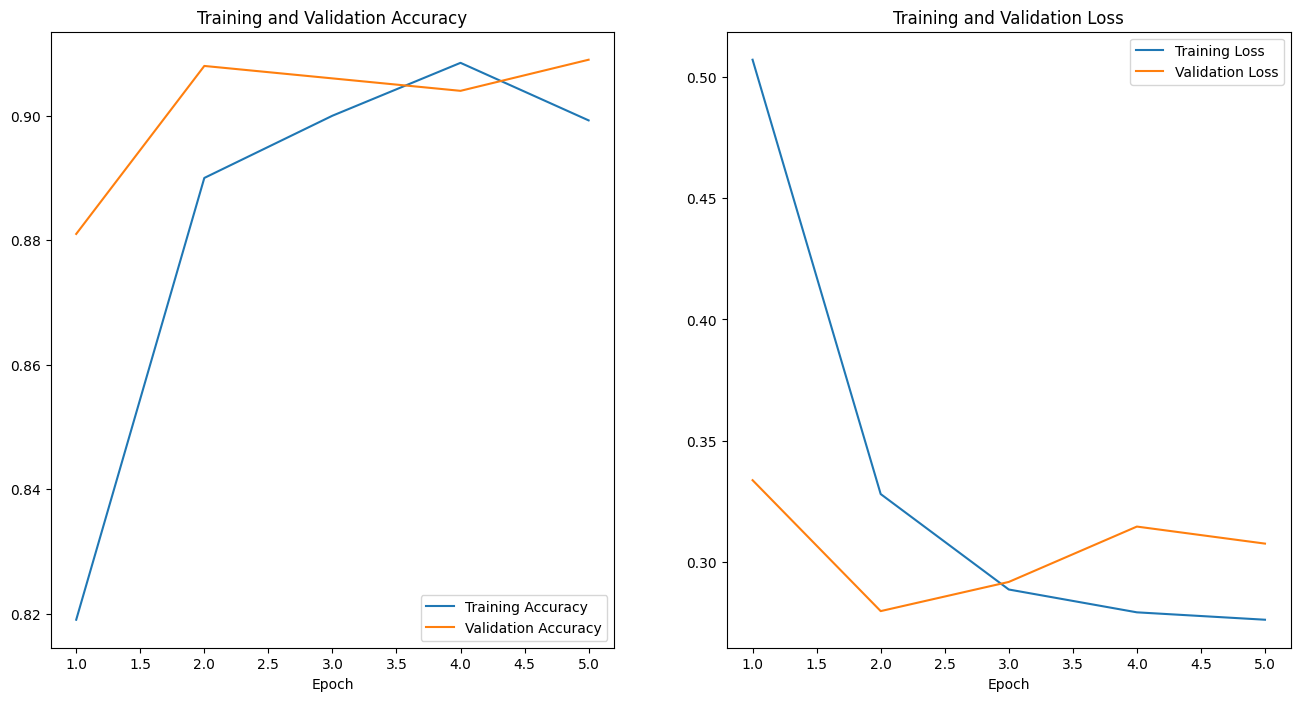

In [7]:
base_learning_rate = 0.001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.summary()

epochs = 5 # Five-epoch CPU run; the starter allows updating this budget.
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs,
  verbose=2
)

vis_history(history)

# Save the same trained-head starting point for both fine-tuning variations.
# Run this whole cell before unfreezing the backbone; do not capture later weights.
frozen_head_weights = model.get_weights()
model.save_weights('frozen_head.weights.h5')


In [8]:
# The new head is trained. Now unfreeze the backbone for fine-tuning.
# Recompile in the next cell so the trainable-parameter change takes effect.
print("And now let's enable trainable flag to the BASE MODEL: ")
base_model.trainable = True
for i, layer in enumerate(model.layers):
   print(i, layer.name, layer.trainable)

And now let's enable trainable flag to the BASE MODEL: 
0 input_layer_2 True
1 sequential True
2 mobilenetv2_1.00_224 True
3 global_average_pooling2d True
4 dropout True
5 dense True


Recorded epoch metrics from Keras History:
Epoch 1/5: accuracy=0.7207, loss=0.8355, val_accuracy=0.8930, val_loss=0.4115
Epoch 2/5: accuracy=0.8043, loss=0.5533, val_accuracy=0.8790, val_loss=0.4946
Epoch 3/5: accuracy=0.8533, loss=0.4180, val_accuracy=0.8600, val_loss=0.4791
Epoch 4/5: accuracy=0.8775, loss=0.3313, val_accuracy=0.8430, val_loss=0.5663
Epoch 5/5: accuracy=0.9050, loss=0.2702, val_accuracy=0.7170, val_loss=1.1050


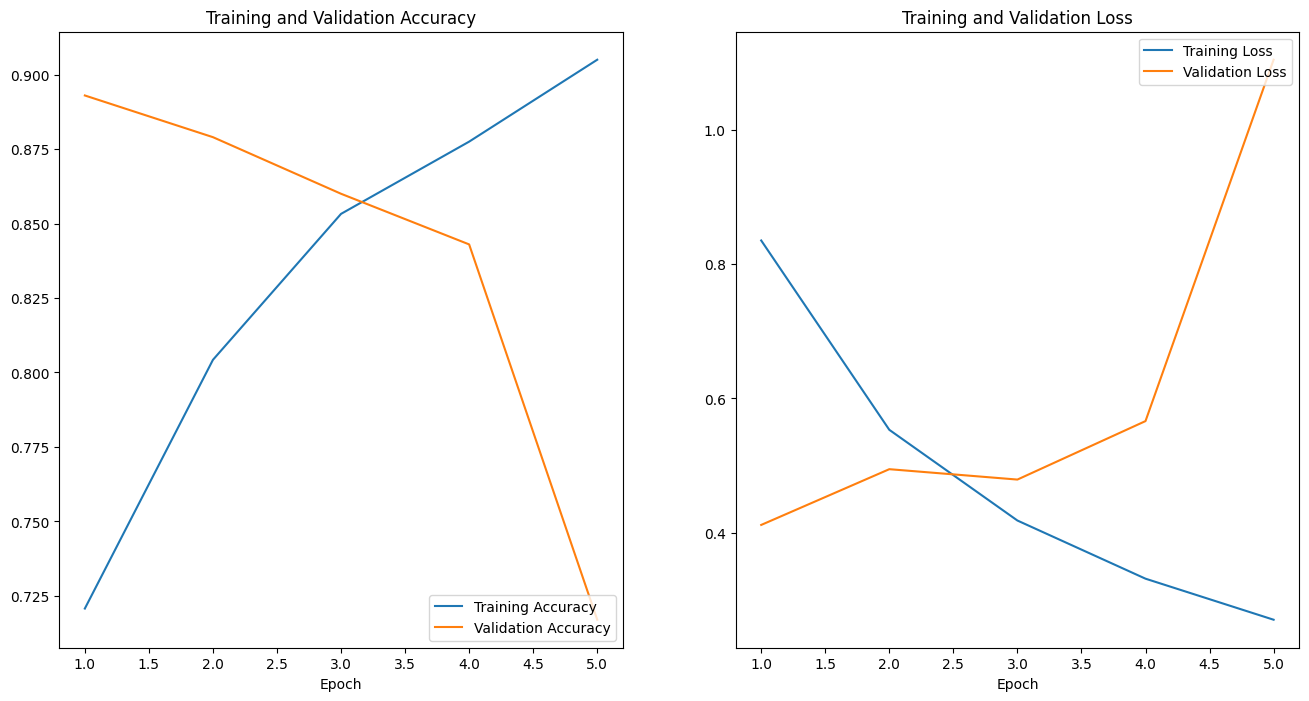

In [9]:
epochs = 5 # Five-epoch CPU run; the starter allows updating this budget.

base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()
history2 = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs,
  verbose=2
)
vis_history(history2)

# Save the model
from pathlib import Path
Path('tmp').mkdir(exist_ok=True)
model.save('tmp/last_finetuned_model.keras')

As a **final experiment, run a few (ONLY 2 or 3) variations to see HOW/IF your changes influence the results**.
- You can change learning rates (where do you think it makes sense to use smaller? larger?), optimizers, batch size, ...
- INSTEAD of just SAVING THE LAST MODEL. you can add this callback to save "check points" of your model (in this case is set to save only the best one found).
More info: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint

You can add plenty of other "utilities" to run during your training process.
More info: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks

We run **two** variations using the existing model, augmentation, preprocessing and dataset split. Each starts from the frozen-head weights saved above, with a fresh optimizer and fresh callbacks, so neither continues training the previous variation:
- **Variation 1:** all backbone layers trainable, Adam learning rate `1e-5` instead of the baseline `1e-4`.
- **Variation 2:** learning rate `1e-5`, but only the last 20 backbone layers are eligible for training; BatchNormalization layers stay frozen.

Both use at most 5 epochs and the same validation-loss checkpoint/early-stopping policy. Report the actual epoch counts: early stopping can shorten a run, and the original baseline did not use this stopping policy. The starter already includes augmentation, so adding another augmentation model is unnecessary for these two comparisons.


In [10]:
# Save the best validation model rather than the best training fit.
# Create NEW callbacks and a separate checkpoint file for each experiment.
from pathlib import Path
Path('tmp').mkdir(exist_ok=True)

def make_callbacks(checkpoint_filepath):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=checkpoint_filepath,
            save_weights_only=True,
            monitor='val_loss',
            mode='min',
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            mode='min',
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ]


In [11]:
# VARIATION 1: all layers, smaller learning rate.
# Reset BOTH the weights and optimizer, rather than continuing the previous run.
base_model.trainable = True
model.set_weights(frozen_head_weights)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
checkpoint_filepath_1 = './tmp/variation1.weights.h5'
callbacks_1 = make_callbacks(checkpoint_filepath_1)


In [12]:
history_variation1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_1,
    verbose=2
)


Recorded epoch metrics from Keras History:
Epoch 1/5: accuracy=0.6718, loss=0.9354, val_accuracy=0.8830, val_loss=0.3827
Epoch 2/5: accuracy=0.7425, loss=0.7241, val_accuracy=0.8300, val_loss=0.5593
Epoch 3/5: accuracy=0.7803, loss=0.6297, val_accuracy=0.7810, val_loss=0.7074
Epoch 4/5: accuracy=0.8023, loss=0.5442, val_accuracy=0.7710, val_loss=0.7194
Epoch 5/5: accuracy=0.8213, loss=0.5208, val_accuracy=0.7910, val_loss=0.6580


In [13]:
# Evaluate the epoch selected by validation LOSS, which need not have peak accuracy.
model.load_weights(checkpoint_filepath_1)
variation1_loss, variation1_accuracy = model.evaluate(val_ds, verbose=0)
print(f'Variation 1 selected checkpoint: loss={variation1_loss:.4f}, accuracy={variation1_accuracy:.2%}')


Variation 1 selected checkpoint: loss=0.3827, accuracy=88.30%


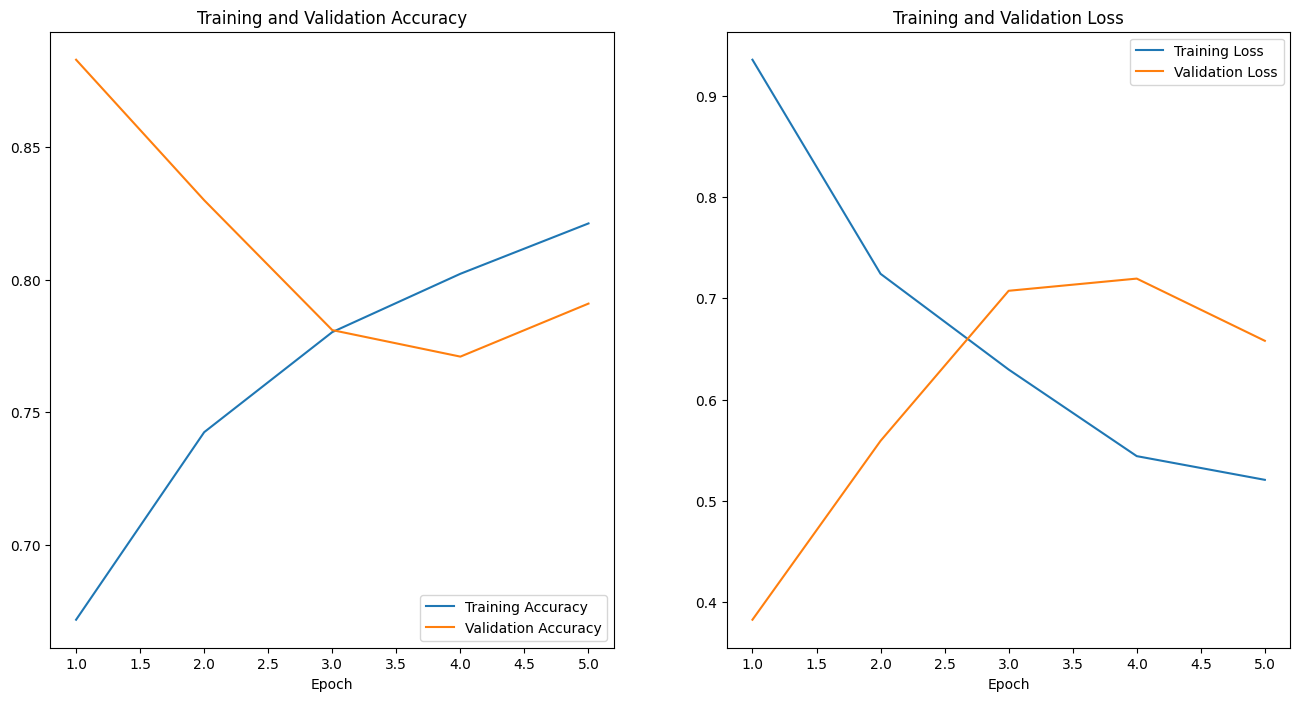

In [14]:
vis_history(history_variation1)


In [15]:
# VARIATION 2: same starting weights and learning rate, fewer trainable layers.
base_model.trainable = True
model.set_weights(frozen_head_weights)

for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# The output remains Dense(5) without softmax, so keep from_logits=True.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


In [16]:
checkpoint_filepath_2 = './tmp/variation2.weights.h5'
callbacks_2 = make_callbacks(checkpoint_filepath_2)


In [17]:
print('Trainable backbone layers in variation 2:',
      sum(layer.trainable for layer in base_model.layers))


Trainable backbone layers in variation 2: 13


Recorded epoch metrics from Keras History:
Epoch 1/5: accuracy=0.9235, loss=0.2124, val_accuracy=0.9150, val_loss=0.2410
Epoch 2/5: accuracy=0.9370, loss=0.1786, val_accuracy=0.9310, val_loss=0.2271
Epoch 3/5: accuracy=0.9395, loss=0.1634, val_accuracy=0.9170, val_loss=0.2644
Epoch 4/5: accuracy=0.9498, loss=0.1434, val_accuracy=0.9300, val_loss=0.2328
Epoch 5/5: accuracy=0.9595, loss=0.1244, val_accuracy=0.9310, val_loss=0.2236


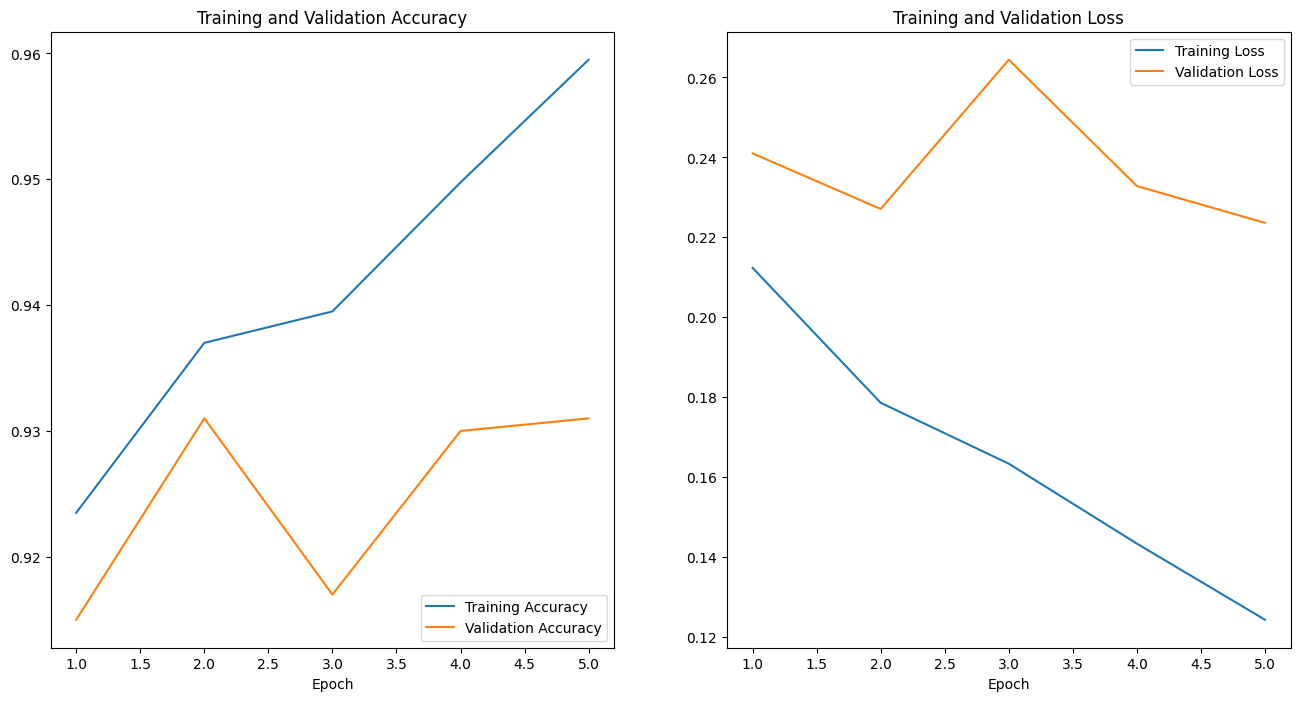

In [18]:
history_variation2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_2,
    verbose=2
)

vis_history(history_variation2)


Comparison of the two variations

All runs keep the augmentation and MobileNetV2 preprocessing already provided in the starter. The summary below reports the measured results. Final-epoch accuracy and the accuracy of the checkpoint selected by minimum validation loss are shown separately.


In [19]:
model.load_weights(checkpoint_filepath_2)
variation2_loss, variation2_accuracy = model.evaluate(val_ds, verbose=0)
print(f'Variation 2 selected checkpoint: loss={variation2_loss:.4f}, accuracy={variation2_accuracy:.2%}')


Variation 2 selected checkpoint: loss=0.2236, accuracy=93.10%


In [20]:
# Measured results for Answer 2.
# Final-epoch metrics and selected-checkpoint metrics are reported separately.
experiments = [
    ('Frozen head, lr=1e-3', history),
    ('All layers, lr=1e-4 (baseline)', history2),
    ('All layers, lr=1e-5', history_variation1),
    ('Last 20 layers (BN frozen), lr=1e-5', history_variation2),
]
print(f"{'Experiment':36s} {'Epochs':>6s} {'Train':>8s} {'Val':>8s} {'Val loss':>9s} {'Peak val':>9s}")
for name, results in experiments:
    h = results.history
    print(f"{name:36s} {len(h['loss']):6d} {h['accuracy'][-1]:8.2%} "
          f"{h['val_accuracy'][-1]:8.2%} {h['val_loss'][-1]:9.4f} {max(h['val_accuracy']):9.2%}")
print(f'Variation 1 selected by minimum val_loss: {variation1_accuracy:.2%} accuracy, loss {variation1_loss:.4f}')
print(f'Variation 2 selected by minimum val_loss: {variation2_accuracy:.2%} accuracy, loss {variation2_loss:.4f}')
print('All values above use the validation set, not an independent test set.')


Experiment                           Epochs    Train      Val  Val loss  Peak val
Frozen head, lr=1e-3                      5   89.92%   90.90%    0.3075    90.90%
All layers, lr=1e-4 (baseline)            5   90.50%   71.70%    1.1050    89.30%
All layers, lr=1e-5                       5   82.13%   79.10%    0.6580    88.30%
Last 20 layers (BN frozen), lr=1e-5       5   95.95%   93.10%    0.2236    93.10%
Variation 1 selected by minimum val_loss: 88.30% accuracy, loss 0.3827
Variation 2 selected by minimum val_loss: 93.10% accuracy, loss 0.2236
All values above use the validation set, not an independent test set.


### **QUESTION 1**. Answer True/False and explain why you think so.

1. After reading the explanations in this notebook, I think when fine-tuning and existing model, we usually start with its layers frozen, but later we should un-freeze *ALL* layers always.

2.   It is essential to make sure when loading the base model, its parameter *weights* are initialized to the pre-trained weigths we want, usually imagenet.

ANSWER 1:
1. **False.** We first train the new classifier with the pretrained backbone frozen. Later we may unfreeze some or all layers, depending on the dataset and validation results; unfreezing everything can overfit or damage useful pretrained features.
2. **True.** To perform transfer learning, we must load the intended pretrained weights (here, ImageNet). Using the same architecture with random weights would train from scratch rather than transfer learned features.


### **QUESTION 2**.
Discuss the results you have obtained with your toy-data after running the different steps of the fine tunning process and the variations you have incorporated.

* How does it compare to the previous tasks in this Lab? What are advantages/disadvantages you find within each option? (max 10 lines).





ANSWER 2: the frozen-head run ends at 89.92% training / 90.90% validation; full fine-tuning at 1e-4 ends at 90.50% / 71.70%.
Full fine-tuning does not improve validation accuracy in this run; adapting every layer is not always beneficial.
The checkpoints selected by minimum validation loss reach 88.30% with all layers at 1e-5 and 93.10% with only the last 20 layers eligible (BN frozen); all runs use five epochs.
The main Task 2 CNN reaches 54.40% validation with 20 epochs, so transfer learning is effective here, although resolution/training budgets differ. The 2NN uses CIFAR-10 and its accuracy is not directly comparable.

|Method|Advantages|Disadvantages|
|---|---|---|
|2NN|Simple to implement and understand.|Flattening loses spatial structure; many weights; evaluated on a different dataset.|
|CNN Simple|Learns local spatial features with shared filters; adapts from scratch.|Needs more data/training; the saved baseline overfits strongly.|
|Fine-Tuning|Reuses useful pretrained features and performs well on these food classes.|Requires matching preprocessing and careful learning rates/freezing; further training may worsen generalization.|
